<center><img src="https://i.imgur.com/zRrFdsf.png" width="700"></center>


# Moving Gas Stations away from Schools in Seattle, WA

# Getting ready

## Installations needed

In [112]:
!pip install osmnx mapclassify

In [210]:
import osmnx as ox

# Configuración de tiempos de espera y reintentos para evitar errores de conexión con Overpass
ox.settings.timeout = 180
ox.settings.requests_timeout = 180
ox.settings.overpass_endpoint = 'https://overpass.kumi.systems/api/interpreter'

## Data needed

### Official data preprocessing

We need the boston map. As we are going to analize schools and gas stations we must omit the water bodies. A good option is:


*   https://www.mass.gov/info-details/massgis-data-municipalities

You will select the shapefile for Boston from there. The file returned will be a zip, which I have saved on GitHub from where I read it:



In [163]:
import geopandas as gpd

filez="https://github.com/rodrigosalazarl-GH/Reubicar_estaciones/raw/main/Data/2020_Census_Tracts_Seattle_8661193084158732132.zip"
seattle=gpd.read_file(filez)
seattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   GEOID20     177 non-null    object  
 1   GROSS_ACRE  177 non-null    float64 
 2   LAND_ACRES  177 non-null    float64 
 3   WATER_ACRE  177 non-null    float64 
 4   NAME        177 non-null    object  
 5   TRACT_NUMB  177 non-null    int64   
 6   BASENAME    177 non-null    object  
 7   UVDA_AREA   177 non-null    object  
 8   CRA_NO      177 non-null    float64 
 9   CRA_GRP     177 non-null    int32   
 10  GEN_ALIAS   177 non-null    object  
 11  DETL_NAMES  177 non-null    object  
 12  C_DISTRICT  177 non-null    int64   
 13  geometry    177 non-null    geometry
dtypes: float64(4), geometry(1), int32(1), int64(2), object(6)
memory usage: 18.8+ KB


As you see, it is just one geometry:

In [164]:
seattle

,GEOID20,GROSS_ACRE,LAND_ACRES,WATER_ACRE,NAME,TRACT_NUMB,BASENAME,UVDA_AREA,CRA_NO,CRA_GRP,GEN_ALIAS,DETL_NAMES,C_DISTRICT,geometry
0,53033000402,444.493643,444.527261,0.000000,Census Tract 4.02,402,4.02,Bitter Lake Village,9.1,9,Broadview/Bitter Lake,"Broadview, Bitter Lake",5,"POLYGON ((1267598.433 267477.138, 1267788.924 ..."
1,53033000403,180.930716,165.408389,15.535762,Census Tract 4.03,403,4.03,Bitter Lake Village,9.1,9,Broadview/Bitter Lake,"Broadview, Bitter Lake",5,"POLYGON ((1265848.993 271492.767, 1265842.812 ..."
2,53033000700,319.838996,319.862596,0.000000,Census Tract 7,700,7,Lake City,8.2,8,Olympic Hills/Victory Heights,"Lake City, Victory Heights, Olympic Hills, Pin...",5,"POLYGON ((1277629.018 265876.292, 1277833.975 ..."
3,53033003302,154.942826,154.952619,0.000000,Census Tract 33.02,3302,33.02,Ballard,10.2,10,Whittier Heights,"Whittier Heights, Loyal Heights, Crown Hill",6,"POLYGON ((1262877.612 251639.607, 1262891.039 ..."
4,53033003601,166.571397,166.583375,0.000000,Census Tract 36.01,3601,36.01,Green Lake - Roosevelt,9.4,9,Green Lake,"Green Lake, Meridian, Roosevelt, Woodland Park",6,"POLYGON ((1274839.167 250046.877, 1274833.189 ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,53033008101,68.690415,66.798515,68.613998,Census Tract 81.01,8101,81.01,Center City,13.2,13,Downtown Commercial Core,"Downtown Commercial Core, West Edge, Central B...",7,"POLYGON ((1268688.847 226501.062, 1268841.791 ..."
173,53033010401,402.739919,402.750637,0.000000,Census Tract 104.01,10401,104.01,Othello,3.5,3,Beacon Hill,Beacon Hill,2,"POLYGON ((1279994.827 207985.661, 1280136.282 ..."
174,53033011401,304.713408,304.719237,0.000000,Census Tract 114.01,11401,114.01,Westwood-Highland Park,2.4,2,Roxhill/Westwood,"Roxhill, Westwood, South Delridge, White Center",1,"POLYGON ((1264535.644 198387.214, 1264519.606 ..."
175,53033011700,868.762098,868.775078,0.000000,Census Tract 117,11700,117,Rainier Beach,3.4,3,South Beacon Hill/NewHolly,"South Beacon Hill, NewHolly, Holly Park",2,"POLYGON ((1280795.738 197846.082, 1280877.933 ..."


The map we have has come projected:

In [165]:
seattle.crs

<Projected CRS: PROJCS["NAD83(HARN) / Washington North (ftUS)",GEO ...>
Name: NAD83(HARN) / Washington North (ftUS)
Axis Info [cartesian]:
- [east]: Easting (US survey foot)
- [north]: Northing (US survey foot)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Lambert Conic Conformal (2SP)
Datum: NAD83 (High Accuracy Reference Network)
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [167]:
seattle = seattle.to_crs(32610)

In [168]:
seattle.crs

<Projected CRS: EPSG:32610>
Name: WGS 84 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 126°W and 120°W, northern hemisphere between equator and 84°N, onshore and offshore. Canada - British Columbia (BC); Northwest Territories (NWT); Nunavut; Yukon. United States (USA) - Alaska (AK).
- bounds: (-126.0, 0.0, -120.0, 84.0)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

### Crowdsourced data pre processing

Now we need the schools and gas stations. Let's become familiar with OpenStreet Maps [API for Python](https://osmnx.readthedocs.io/en/stable/), which for our case would be very useful.

You can get the gas stations from Boston like this:


In [211]:
# Get gas stations in Boston
import osmnx as ox

# Configurar tiempos de espera (en segundos) y reintentos del servidor
ox.settings.timeout = 180
ox.settings.requests_timeout = 180
ox.settings.overpass_endpoint = 'https://overpass.kumi.systems/api/interpreter'

stations = ox.features_from_place("Seattle, Washington, USA",
                                tags={'amenity': 'fuel'})
# En versiones recientes de OSMnx, estas configuraciones modifican el cliente HTTP interno

Notice we are getting several gas stations, already as a GDF:

In [177]:
stations.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 128 entries, ('node', np.int64(457773031)) to ('way', np.int64(1460417274))
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   geometry                   128 non-null    geometry
 1   amenity                    128 non-null    object  
 2   brand                      111 non-null    object  
 3   brand:wikidata             109 non-null    object  
 4   name                       122 non-null    object  
 5   addr:city                  47 non-null     object  
 6   addr:housenumber           51 non-null     object  
 7   addr:postcode              46 non-null     object  
 8   addr:street                51 non-null     object  
 9   check_date                 65 non-null     object  
 10  compressed_air             60 non-null     object  
 11  opening_hours              51 non-null     object  
 12  website                    49 

OSM gave you stations unprojected:

In [178]:
stations.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

Notice the multi-index:

In [179]:
stations

geometry amenity  \
element id                                                                      
node    457773031                         POINT (-122.39997 47.63939)    fuel   
        631386821                          POINT (-122.3203 47.62518)    fuel   
        771801423                         POINT (-122.35525 47.73205)    fuel   
        1197964284                        POINT (-122.32958 47.58001)    fuel   
        1489962206                        POINT (-122.32805 47.66483)    fuel   
...                                                               ...     ...   
way     684913608   POLYGON ((-122.37612 47.5448, -122.37623 47.54...    fuel   
        727276570   POLYGON ((-122.33603 47.53219, -122.33603 47.5...    fuel   
        940949039   POLYGON ((-122.26383 47.68144, -122.26394 47.6...    fuel   
        1106778201  POLYGON ((-122.30916 47.57672, -122.30956 47.5...    fuel   
        1460417274  POLYGON ((-122.29762 47.5779, -122.29746 47.57...    fuel   

                       brand brand:wikidata                          name  \
element id                                                                  
node    457773031    Chevron        Q319642              Magnolia Chevron   
        631386821         76       Q1658320                            76   
        771801423    Chevron        Q319642                       Chevron   
        1197964284     Shell     Q110716465                         Shell   
        1489962206  7-Eleven        Q259340                      7-Eleven   
...                      ...            ...                           ...   
way     684913608        NaN            NaN  Gasco & South Seattle Market   
        727276570      Shell     Q110716465                       Shree's   
        940949039   7-Eleven        Q259340                      7-Eleven   
        1106778201  Sinclair            NaN                           NaN   
        1460417274      Arco        Q304769                          Arco   

                   addr:city addr:housenumber addr:postcode  \
element id                                                    
node    457773031        NaN              NaN           NaN   
        631386821    Seattle              915         98102   
        771801423        NaN              NaN           NaN   
        1197964284       NaN              NaN           NaN   
        1489962206       NaN              NaN           NaN   
...                      ...              ...           ...   
way     684913608        NaN              NaN           NaN   
        727276570    Seattle              140         98106   
        940949039        NaN              NaN           NaN   
        1106778201       NaN              NaN           NaN   
        1460417274       NaN              NaN           NaN   

                                addr:street  check_date  ... start_date  \
element id                                               ...              
node    457773031                       NaN         NaN  ...        NaN   
        631386821           East Roy Street  2024-08-13  ...        NaN   
        771801423                       NaN         NaN  ...        NaN   
        1197964284                      NaN         NaN  ...        NaN   
        1489962206                      NaN  2026-02-18  ...        NaN   
...                                     ...         ...  ...        ...   
way     684913608                       NaN         NaN  ...        NaN   
        727276570   Southwest Kenyon Street         NaN  ...        NaN   
        940949039                       NaN         NaN  ...        NaN   
        1106778201                      NaN         NaN  ...        NaN   
        1460417274                      NaN         NaN  ...        NaN   

                   fuel:e85 maxheight contact:facebook contact:instagram  \
element id                                                                 
node    457773031       NaN       NaN              NaN   

In the multi index you see **nodes**, **relations**, and **ways**:

In [180]:
stations.index

MultiIndex([('node',  457773031),
            ('node',  631386821),
            ('node',  771801423),
            ('node', 1197964284),
            ('node', 1489962206),
            ('node', 2266423106),
            ('node', 2702032640),
            ('node', 2702054487),
            ('node', 2995124967),
            ('node', 5283345524),
            ...
            ( 'way',  600101678),
            ( 'way',  600101691),
            ( 'way',  600101760),
            ( 'way',  603557992),
            ( 'way',  616232144),
            ( 'way',  684913608),
            ( 'way',  727276570),
            ( 'way',  940949039),
            ( 'way', 1106778201),
            ( 'way', 1460417274)],
           names=['element', 'id'], length=128)

Some formatting may be needed at this stage:

- This will put current indexes back into the data, and numbers will appear:

In [181]:
stations.reset_index(drop=False,inplace=True)
stations.head()

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source
0,node,457773031,POINT (-122.39997 47.63939),fuel,Chevron,Q319642,Magnolia Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,node,631386821,POINT (-122.3203 47.62518),fuel,76,Q1658320,76,Seattle,915,98102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,node,771801423,POINT (-122.35525 47.73205),fuel,Chevron,Q319642,Chevron,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,node,1197964284,POINT (-122.32958 47.58001),fuel,Shell,Q110716465,Shell,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,node,1489962206,POINT (-122.32805 47.66483),fuel,7-Eleven,Q259340,7-Eleven,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- Keep some columns:

In [183]:
colsToKeep=['element','name','geometry']
fuelSeattle=stations[colsToKeep].copy()

- Reproject the data:

In [186]:
Seattle_crs = "EPSG:32610"

fuelSeattle = fuelSeattle.to_crs(Seattle_crs)

In [187]:
seattle.crs

<Projected CRS: EPSG:32610>
Name: WGS 84 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 126°W and 120°W, northern hemisphere between equator and 84°N, onshore and offshore. Canada - British Columbia (BC); Northwest Territories (NWT); Nunavut; Yukon. United States (USA) - Alaska (AK).
- bounds: (-126.0, 0.0, -120.0, 84.0)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

- Review:

In [188]:
fuelSeattle.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   element   128 non-null    object  
 1   name      122 non-null    object  
 2   geometry  128 non-null    geometry
dtypes: geometry(1), object(2)
memory usage: 3.1+ KB


- From above, columns **name** of the gas station has missing values. We should rename those missing values:

In [189]:
fuelSeattle.fillna({'name':'Unknown'},inplace=True)

- We usually use the names as row index. But row index should not have duplicates. Since several 'names' are the same (_Unknown_), we have to create new names:

In [190]:
fuelSeattle.index.astype(str)+"_"+fuelSeattle.name

,0
0,0_Magnolia Chevron
1,1_76
2,2_Chevron
3,3_Shell
4,4_7-Eleven
...,...
123,123_Gasco & South Seattle Market
124,124_Shree's
125,125_7-Eleven
126,126_Unknown


Then,

In [191]:
fuelSeattle['newname']=fuelSeattle.index.astype(str)+"_"+fuelSeattle.name
fuelSeattle.set_index('newname',inplace=True)
fuelSeattle.drop(columns=['name'],inplace=True)
fuelSeattle.head()

,element,geometry
newname,,
0_Magnolia Chevron,node,POINT (545070.577 5276395.041)
1_76,node,POINT (551068.412 5274865.552)
2_Chevron,node,POINT (548343.649 5286720.849)
3_Shell,node,POINT (550414.847 5269839.108)
4_7-Eleven,node,POINT (550448.153 5279266.856)


See that **nodes** are points, **ways** are lines or simple shapes built from points, and **relations** are conceptual containers that group any of the other elements to represent complex features.

Let me compare with the geometries available:


In [194]:
import pandas as pd

pd.crosstab(fuelSeattle.element,fuelSeattle.geometry.geom_type, margins=True)


col_0,Point,Polygon,All
element,,,
node,17,0,17
way,0,111,111
All,17,111,128


This is the 'relation' we have:

In [193]:
#original data
stations[stations.element=='relation']

,element,id,geometry,amenity,brand,brand:wikidata,name,addr:city,addr:housenumber,addr:postcode,...,start_date,fuel:e85,maxheight,contact:facebook,contact:instagram,contact:phone,contact:twitter,contact:youtube,landuse,mapwithai:source


/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

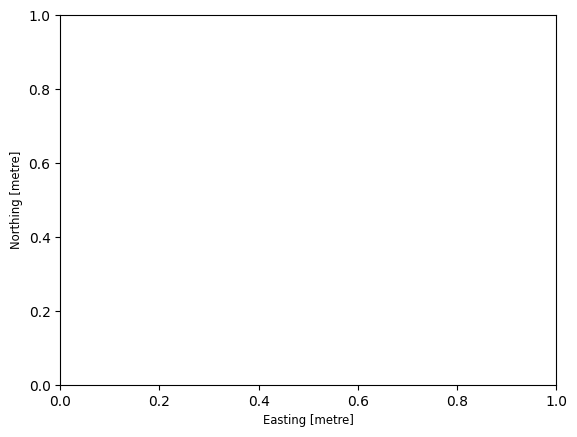

In [195]:
fuelSeattle[fuelSeattle.element=='relation'].plot()

Let me get the schools:

In [198]:
# Get schools in Seattle
schools = ox.features_from_place("Seattle, Washington, USA",
                                tags={'amenity': 'school'})
schools.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 217 entries, ('node', np.int64(356540545)) to ('way', np.int64(1547977369))
Data columns (total 74 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   geometry                 217 non-null    geometry
 1   amenity                  217 non-null    object  
 2   check_date               26 non-null     object  
 3   ele                      140 non-null    object  
 4   gnis:feature_id          146 non-null    object  
 5   name                     215 non-null    object  
 6   addr:city                158 non-null    object  
 7   addr:housenumber         166 non-null    object  
 8   addr:postcode            157 non-null    object  
 9   addr:street              166 non-null    object  
 10  opening_hours            36 non-null     object  
 11  website                  111 non-null    object  
 12  religion                 25 non-null     object  
 13  nam

Let's reformat this as we did before:

In [200]:
schools.reset_index(inplace=True)
schoolSeattle=schools[['element','name','geometry']].copy()
schoolSeattle.fillna({'name':'Unknown'},inplace=True)
schoolSeattle['newname']=schoolSeattle.index.astype(str)+"_"+schoolSeattle.name
schoolSeattle.set_index('newname',inplace=True)
schoolSeattle.drop(columns=['name'],inplace=True)
schoolSeattle = schoolSeattle.to_crs(Seattle_crs)
schoolSeattle.head()


,element,geometry
newname,,
0_Mapleleaf School,node,POINT (552925.436 5283350.335)
1_Hazel Wolf K-8,node,POINT (550876.028 5280652.219)
2_Epic Life Academy,node,POINT (549394.116 5283758.769)
3_Christ the King Elementary School,node,POINT (548515.145 5284662.849)
4_Assumption Saint Bridget School,node,POINT (553072.046 5280365.741)


See element vs geo:

In [201]:
pd.crosstab(schoolSeattle.element,schoolSeattle.geometry.geom_type, margins=True)

col_0,MultiPolygon,Point,Polygon,All
element,,,,
node,0,54,0,54
relation,4,0,2,6
way,0,0,157,157
All,4,54,159,217


In [202]:
#original data
schools[(schools.element=='relation') & (schools.geometry.geom_type=='MultiPolygon')]

,index,element,id,geometry,amenity,check_date,ele,gnis:feature_id,name,addr:city,...,building:levels,fax,short_name,start_date,addr:housename,nursery,preschool,school:language,layer,type
54,54,relation,537423,"MULTIPOLYGON (((-122.2931 47.57649, -122.29298...",school,NaN,28,1505026,Franklin High School,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
56,56,relation,4764405,"MULTIPOLYGON (((-122.31777 47.64223, -122.3176...",school,NaN,62,1515690,Seattle Preparatory School,Seattle,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
57,57,relation,7616973,"MULTIPOLYGON (((-122.33765 47.69496, -122.3376...",school,NaN,NaN,NaN,Cascadia Elementary School,Seattle,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon
59,59,relation,18609000,"MULTIPOLYGON (((-122.26364 47.67391, -122.2636...",school,NaN,NaN,NaN,Sand Point Elementary School,Seattle,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,multipolygon


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

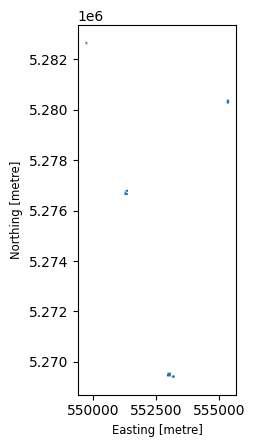

In [203]:
schoolSeattle[(schoolSeattle.element=='relation') & (schoolSeattle.geometry.geom_type=='MultiPolygon')].plot()

In [213]:
base=seattle.explore(tiles='OpenTopoMap',
    attr='Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)',color='lightblue')
schoolSeattle.explore(m=base,color='k')
fuelSeattle.explore(m=base,color='red')

# Explore proximity:


Let's compute a couple of distance matrices.

- The distance among fuel stations

In [215]:
D_Matrix_fuel_fuel=fuelSeattle.geometry.apply\
(lambda station: fuelSeattle.geometry.distance(station))

D_Matrix_fuel_fuel

newname,0_Magnolia Chevron,1_76,2_Chevron,3_Shell,4_7-Eleven,5_7-Eleven,6_Morrison's North Star Marine,7_Shilshole Fuel Dock,8_Dr. Dan's Biodiesel,9_76,...,118_Chevron,119_76,120_Chevron,121_Safeway Fuel Station,122_Shell,123_Gasco & South Seattle Market,124_Shree's,125_7-Eleven,126_Unknown,127_Arco
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,0.000000,6189.778099,10832.142979,8458.219249,6096.362935,3911.871820,4154.629544,4607.185893,3684.919842,6799.259673,...,11032.720301,8059.083730,8471.490011,11342.071122,8388.488702,10650.766388,12839.472695,11229.479609,9704.676294,10259.885224
1_76,6189.778099,0.000000,12164.390410,5068.756372,4444.794018,7396.837510,2913.822486,9025.058016,5776.876534,2146.281615,...,10502.171854,9283.591945,5828.349523,6582.987118,3490.937461,9859.853435,10391.001557,7544.714281,5423.572544,5486.468930
2_Chevron,10832.142979,12164.390410,0.000000,17008.322965,7745.382606,6939.794167,9680.781667,6982.575734,7498.129000,14199.195661,...,3434.731016,2961.691541,7436.375075,18706.121900,15655.292108,20857.745520,22251.515513,8863.786937,17578.604974,17632.751402
3_Shell,8458.219249,5068.756372,17008.322965,0.000000,9427.806838,11287.548358,7342.660400,12635.016000,9933.327452,2922.512744,...,15557.714940,14059.287367,10879.733945,3206.070889,2163.657924,5243.026228,5325.665547,12298.163104,1528.265114,2402.851126
4_7-Eleven,6096.362935,4444.794018,7745.382606,9427.806838,0.000000,4594.203464,2537.458079,6272.831613,3095.924539,6540.437675,...,6182.494529,4939.340577,2378.849213,10960.740771,7927.629559,13808.912707,14744.043923,5152.034055,9868.081904,9889.821437
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,10650.766388,9859.853435,20857.745520,5243.026228,13808.912707,14330.734414,11384.887382,15256.296547,13384.622284,7840.707251,...,19975.906239,17895.800660,15622.732075,7048.807065,7406.644471,0.000000,3320.967459,17353.381510,6121.528764,6950.536820
124_Shree's,12839.472695,10391.001557,22251.515513,5325.665547,14744.043923,16185.514303,12571.965336,17343.197545,14990.551645,8245.361423,...,20883.253836,19286.809328,16183.027772,5393.694936,7165.874001,3320.967459,0.000000,17427.534450,5304.377123,5824.618469
125_7-Eleven,11229.479609,7544.714281,8863.786937,12298.163104,5152.034055,9340.534273,7314.479491,10839.148958,8108.038042,9514.437711,...,5617.194131,7342.966295,2828.590101,12564.668105,10253.850567,17353.381510,17427.534450,0.000000,12100.385190,11735.314154


From here, we can compute the minimal distance among those gas stations:

In [216]:
D_Matrix_fuel_fuel.replace(0,None,inplace=True) # avoid the zero
D_Matrix_fuel_fuel.min(axis=1).sort_values().head(10)

,0
newname,
104_ARCO,3.577986
103_ARCO,3.577986
89_76,4.467367
88_76,4.467367
30_Chevron,9.231022
11_Chevron,9.231022
91_Shell,10.521046
90_Shell,10.521046
60_Pacific Pride,12.428133


- The distance among gas stations and schools:

In [218]:
D_Matrix_fuel_school=fuelSeattle.geometry.apply\
(lambda station: schoolSeattle.geometry.distance(station))

D_Matrix_fuel_school

newname,0_Mapleleaf School,1_Hazel Wolf K-8,2_Epic Life Academy,3_Christ the King Elementary School,4_Assumption Saint Bridget School,5_Saint Edward Parish School,6_Learning Way School,7_Concordia Lutheran School,8_Northwest Montessori School,9_Northwest Childrens Academy,...,207_Rainier Valley Leadership Academy,208_Eckstein Middle School,209_La Escuelita Bilingual School,210_Impact | Salish Sea Elementary,211_Little Laurels,212_Cascade Parent Partnership Program,213_Roxhill Elementary School,214_Downtown School,215_Seattle Waldorf School - Main Campus,216_Mercer International Middle School
newname,,,,,,,,,,,,,,,,,,,,,
0_Magnolia Chevron,10491.659688,7199.084975,8539.173303,8956.657111,8932.523151,13341.958719,13507.709663,9506.260725,4487.653029,5324.737909,...,13761.296382,9053.687052,7195.602311,14410.390399,12230.115714,3124.787461,13580.295215,4054.694024,10282.565861,10565.424327
1_76,8685.624613,5789.863861,9049.451299,10124.534305,5853.770242,8808.620825,11975.722628,6599.617370,5074.222149,880.126226,...,9194.797832,6402.592462,6089.745057,10238.137431,10878.978200,3673.708903,12398.535914,2554.619356,8612.096410,6727.699624
2_Chevron,5687.981663,6575.805111,3142.833012,2065.133147,7921.183151,20929.652730,23474.696332,7563.706626,7465.701803,11654.725826,...,21301.486962,7045.990100,6198.145060,22392.998311,4983.299677,9477.043229,23725.977819,12427.156563,5446.866034,18854.337587
3_Shell,13742.500324,10822.941478,13957.036131,14944.971496,10856.827909,4930.152593,6965.257592,11596.129786,9605.655199,5388.607746,...,5347.980500,11437.825204,11106.714608,5956.588399,15939.807496,7649.546886,7450.088356,4780.314108,13675.664902,2107.909975
4_7-Eleven,4776.163021,1449.933898,4613.922112,5731.776499,2844.708492,13184.453100,16181.746778,3413.989799,1921.307178,4045.349103,...,13557.409322,2975.949318,1688.226327,14650.612357,6843.922073,3022.474841,16531.995201,5311.494858,4626.744314,11169.644124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123_Gasco & South Seattle Market,18437.654830,15257.637660,18016.092365,18818.447391,15701.177153,7223.804112,2917.573907,16447.522259,13440.851728,9890.137026,...,7489.956010,16219.730566,15482.629187,7043.580298,20596.596877,11308.744575,2917.011727,8493.599402,18333.769196,5192.808772
124_Shree's,19046.714482,16146.376840,19238.321146,20186.490665,16131.338043,4633.509651,2212.511637,16863.752907,14799.205507,10699.306284,...,4762.577365,16729.265592,16426.505984,3973.425033,21246.496324,12755.913237,2957.170911,9823.178035,18986.753055,3812.301432
125_7-Eleven,3191.366019,4396.077208,6402.128582,7587.141782,2308.936140,14581.418422,19250.984757,1890.496999,6978.426106,7738.111508,...,14859.036606,2191.162884,4562.774267,16156.189878,4800.640849,8052.316222,19748.085148,9560.847169,3273.765496,13416.903822


# Decision 1: Find the stations that should go away



Now, we could compute the minimal distance from a gas station to a school, and sort the stations by that value:

In [219]:
D_Matrix_fuel_school.min(axis=1).sort_values().head(10)

,0
newname,
102_Shell,0.824760
38_Shell,23.258460
69_Shell,36.646314
1_76,75.072216
111_Space Age,91.233431
74_Shell,94.493039
109_Shell,97.053490
96_Chevron,100.324890
36_Chevron,112.051912


By the previous exploration, we may decide that no station should at 200 or less from a school:

In [220]:
mindDist=200

# Decision 2: Secure perimeter of every school

Let's create the safe area around the school. This requires **buffer**:

In [222]:
schoolSeattle_buffered=schoolSeattle.buffer(mindDist)
schoolSeattle_buffered

,0
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


In [223]:
#remember we have
type(schoolSeattle_buffered)

geopandas.geoseries.GeoSeries

Turning GS into GDF:

In [224]:
secured_schoolSeattle=gpd.GeoDataFrame(geometry=schoolSeattle_buffered)
secured_schoolSeattle

,geometry
newname,
0_Mapleleaf School,"POLYGON ((553125.436 5283350.335, 553124.473 5..."
1_Hazel Wolf K-8,"POLYGON ((551076.028 5280652.219, 551075.065 5..."
2_Epic Life Academy,"POLYGON ((549594.116 5283758.769, 549593.153 5..."
3_Christ the King Elementary School,"POLYGON ((548715.145 5284662.849, 548714.182 5..."
4_Assumption Saint Bridget School,"POLYGON ((553272.046 5280365.741, 553271.083 5..."
...,...
212_Cascade Parent Partnership Program,"POLYGON ((548097.853 5277444.55, 548200.996 52..."
213_Roxhill Elementary School,"POLYGON ((547208.545 5263118.173, 547211.211 5..."
214_Downtown School,"POLYGON ((548577.36 5274495.399, 548596.968 52..."


Buffers created polygons:

In [225]:
secured_schoolSeattle.geometry.geom_type.value_counts()

,count
Polygon,217


# Decision 3: Standardized Gas stations geometries

Not all gas stations are points:

In [226]:
fuelSeattle.geometry.geom_type.value_counts()

,count
Polygon,111
Point,17


The point is a simple representation. Then let's make a buffer of 10 meters for every station to make sure the station is selected even if we just had one of its points.

In [227]:
fuelSeattle_allPoly=fuelSeattle.copy()
fuelSeattle_allPoly['geometry'] = [
    station.buffer(10) if station.geom_type == 'Point' else station
    for station in fuelSeattle.geometry
]

In [228]:
# rechecking
fuelSeattle_allPoly.geometry.geom_type.value_counts()

,count
Polygon,128


# Decision 4: Overlay or SJoin to determine gas stations in trouble

This is great moment to test our understanding of these ops:

- do you want to move the points from the gas stations that are close to the schools?

In [230]:
fuelSeattle_allPoly.overlay(secured_schoolSeattle,how='intersection',keep_geom_type=False)

,element,geometry
0,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
1,node,"POLYGON ((551078.363 5274864.572, 551078.219 5..."
2,node,"POLYGON ((550424.799 5269838.128, 550424.655 5..."
3,node,"POLYGON ((545961.026 5280205.552, 545960.882 5..."
4,node,"POLYGON ((553782.981 5266125.595, 553782.837 5..."
5,node,"POLYGON ((548171.127 5263444.827, 548170.983 5..."
6,way,"POLYGON ((549200.164 5283742.752, 549194.91 52..."
7,way,"POLYGON ((546272.901 5269904.828, 546264.427 5..."
8,way,"POLYGON ((552390.26 5272921.863, 552382.489 52..."
9,way,"POLYGON ((552390.26 5272921.863, 552382.489 52..."


- do you want to move the gas stations that are close to the schools?

In [229]:
fuelSeattle_allPoly.sjoin(secured_schoolSeattle,how='inner',predicate='intersects')

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.808, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School


The obvious choice is using **sjoin** + **intersects** (why not within?).

In [231]:
gas_relocate=fuelSeattle_allPoly.sjoin(secured_schoolSeattle,how='inner',predicate='intersects')

It is possible the index may have duplicates:

In [232]:
is_duplicate = gas_relocate.index.duplicated(keep=False)

gas_relocate[is_duplicate]

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",152_Lowell Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",187_Nova High School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",198_Seattle World School
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",116_Morningside Academy
69_Shell,way,"POLYGON ((551874.231 5273802.685, 551871.234 5...",51_The Hatch School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",198_Seattle World School
72_7-Eleven,way,"POLYGON ((551684.055 5273748.468, 551690.484 5...",116_Morningside Academy


Remember our names are on the row index, then:

In [233]:
# put the index as a column: reset_index(drop=False)
# drop duplicates in that column:drop_duplicates(subset='newname_left')
# column bask to index : set_index('newname_left')

gas_relocate.reset_index(drop=False).\
drop_duplicates(subset='newname_left').\
set_index('newname_left')

,element,geometry,newname_right
newname_left,,,
1_76,node,"POLYGON ((551078.412 5274865.552, 551078.363 5...",41_St. Nicholas School
3_Shell,node,"POLYGON ((550424.847 5269839.108, 550424.799 5...",18_Career Link School
5_7-Eleven,node,"POLYGON ((545961.074 5280206.532, 545961.026 5...",139_Adams Elementary School
13_Chevron,node,"POLYGON ((553783.029 5266126.575, 553782.981 5...",169_Aki Kurose Middle School
14_Gas & Smoke Depot,node,"POLYGON ((548171.175 5263445.808, 548171.127 5...",6_Learning Way School
19_Arco,way,"POLYGON ((549199.723 5283761.099, 549200.164 5...",2_Epic Life Academy
21_Safeway,way,"POLYGON ((546272.699 5269920.842, 546272.901 5...",98_Lafayette Elementary School
25_Arco,way,"POLYGON ((552390.065 5272931.786, 552390.26 52...",76_Garfield High School
34_Chevron,way,"POLYGON ((546913.57 5282556.957, 546902.092 52...",199_Whitman Middle School


In [234]:
#making the actual change
gas_relocate= gas_relocate.reset_index(drop=False).drop_duplicates(subset='newname_left').\
              set_index('newname_left')

Let's see both schools and those stations to relocate:

In [237]:
base=secured_schoolSeattle.sjoin(gas_relocate,how='inner',predicate='intersects').explore(color='yellow', tiles='OpenTopoMap',
    attr='Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)')
gas_relocate.explore(m=base,color='red')

# Decision 5: Find suitable places for the stations in trouble


We can not put the gas stations anywhere. They need to be situated on driveable routes, not inside a house or building.


- Find suitable locations along routes

Let's get the streets from Boston with the help of OSM:

In [238]:
# Define the place
place = "Seattle, Washington, USA"

# Download the street network graph for Boston
G = ox.graph_from_place(place, network_type="drive")

# Convert the graph edges (streets) to a GeoDataFrame
streets = ox.graph_to_gdfs(G, nodes=False, edges=True)

streets.shape

(50301, 15)

You see we got a huge set of routes:

In [239]:
streets.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
MultiIndex: 50301 entries, (np.int64(29445663), np.int64(29485641), np.int64(0)) to (np.int64(14237930653), np.int64(53073730), np.int64(0))
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   osmid     50301 non-null  object  
 1   highway   50301 non-null  object  
 2   lanes     38813 non-null  object  
 3   maxspeed  49897 non-null  object  
 4   oneway    50301 non-null  bool    
 5   ref       749 non-null    object  
 6   reversed  50301 non-null  object  
 7   length    50301 non-null  float64 
 8   geometry  50301 non-null  geometry
 9   bridge    484 non-null    object  
 10  name      44926 non-null  object  
 11  tunnel    59 non-null     object  
 12  junction  4742 non-null   object  
 13  access    237 non-null    object  
 14  width     270 non-null    object  
dtypes: bool(1), float64(1), geometry(1), object(12)
memory usage: 7.0+ MB


Let's pay attention to the 'highway' column:

In [240]:
streets.highway.value_counts().index

Index([                    'residential',                        'tertiary',
                             'secondary',                         'primary',
                          'unclassified',                   'motorway_link',
                                 'trunk',                        'motorway',
                          'primary_link',                  'secondary_link',
                         'tertiary_link',                   'living_street',
         ['unclassified', 'residential'],                      'trunk_link',
                                'busway',         ['tertiary', 'secondary'],
                ['primary', 'secondary'],  ['living_street', 'residential'],
           ['motorway_link', 'motorway'],     ['residential', 'trunk_link'],
            ['unclassified', 'tertiary'],       ['tertiary', 'residential'],
              ['tertiary', 'trunk_link'], ['residential', 'secondary_link'],
          ['tertiary', 'secondary_link'],     ['primary_link', 'secondary']]

In [241]:
GAS_STATION_ROAD_TYPES = [
    'motorway',      # High-speed limited access roads
    'primary',       # Major national roads
    'trunk',         # Important regional roads
    'motorway_link', # Motorway entrance/exit ramps
    'primary_link',  # Primary road connectors
    'trunk_link',     # Trunk road connectors
    ['motorway', 'trunk'],
    ['primary', 'motorway_link'],
    ['primary', 'primary_link']
]

suitable_roads = streets[streets.highway.isin(GAS_STATION_ROAD_TYPES)]

suitable_roads.shape

(3709, 15)

Let's reproject:

In [242]:
suitable_roads = suitable_roads.to_crs(seattle.crs)

The possible locations should be:
- Far enough from schools. They should be far from the GDF **secured_schoolBoston** (already buffered with a secure radius) .
- Far from other Gast stations. From **fuelBoston_allPoly** we could add a secured distance. This GDF was was buffered, but just to include the building, so we need to re buffer.

Then, we need to create a buffer around the stations:

In [244]:
competitionDistance=100 # a safe value from above 'D_Matrix_fuel_fuel'
fuelBoston_allPoly_buffered=fuelBoston_allPoly.buffer(competitionDistance)

Do we have a GDF?

In [245]:
type(fuelSeattle_allPoly_buffered)

geopandas.geoseries.GeoSeries

In [249]:
# Generar la variable correcta de Seattle con la capitalización adecuada
fuelSeattle_allPoly_buffered = fuelSeattle_allPoly.buffer(competitionDistance)
secured_fuelSeattle_allPoly = gpd.GeoDataFrame(geometry=fuelSeattle_allPoly_buffered)

Let's combine the secured areas:



In [250]:
secured_areas_dissolved=secured_fuelSeattle_allPoly.overlay(secured_schoolSeattle,how='union',keep_geom_type=False).dissolve()
secured_areas=gpd.GeoDataFrame(geometry=secured_areas_dissolved.geometry)

- Filter the roads. We can NOT choose a location that intersects with the secured areas:

Choose: **overlay** vs **sjoin** vs **clip**?

In [ ]:
suitable_roads.clip(secured_areas,keep_geom_type=False).plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

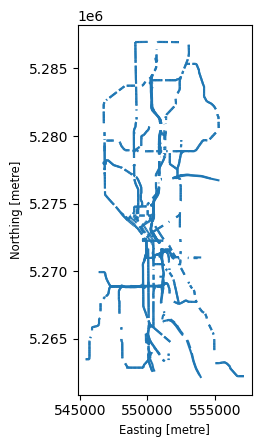

In [251]:
suitable_roads.overlay(secured_areas,keep_geom_type=False, how='difference').plot()

In [ ]:
suitable_roads.sjoin(secured_areas, predicate='intersects').plot()

Why **clip** is a poor choice?
- Keeps only the parts that overlap with the mask. We want the opposite - to remove the overlapping parts (this would give you only roads inside school zones (the exact opposite!))

Why **sjoin** is a poor choice?
- You do get the precise locations that should not be included, you get the whole row element (more area). Since sjoin does not have a **not-intersects** predicate, this will also be wrong:

```
bad_geoms = suitable_roads.clip(secured_areas)
good_segments = suitable_roads.overlay(bad_geoms, how='difference')
```

Then:

In [252]:
good_routes_forGas_dissolved=suitable_roads.overlay(secured_areas,keep_geom_type=False, how='difference').dissolve()
good_routes_forGas=gpd.GeoDataFrame(geometry=good_routes_forGas_dissolved.geometry)
good_routes_forGas

,geometry
0,"MULTILINESTRING ((551005.064 5276789.854, 5510..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

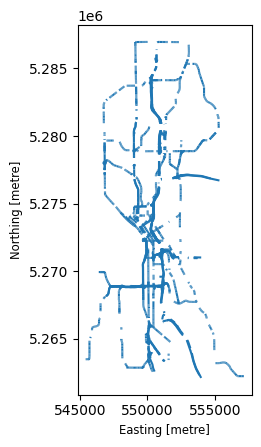

In [253]:
good_routes_forGas.plot()

We may choose a location from those places:

In [261]:
import random

potential_Locations = good_routes_forGas.copy()
newPOLYGONS = []
pointsComputed = 1
attempts = 1

while pointsComputed <= len(gas_relocate):
    # Separamos en líneas individuales sencillas (LineString)
    exploded_locations = potential_Locations.explode(index_parts=False)

    if exploded_locations.empty:
        break

    # Seleccionamos una línea al azar de las opciones disponibles
    random_line = exploded_locations.geometry.sample(1).iloc[0]

    # Generamos un punto aleatorio a lo largo de esa línea (interpolando una distancia aleatoria)
    random_fraction = random.random()
    random_point = random_line.interpolate(random_fraction, normalized=True)

    # Creamos el GeoDataFrame del buffer de 100 metros para el candidato
    candidateStation = gpd.GeoDataFrame(geometry=[random_point.buffer(100)], crs=potential_Locations.crs)

    # Si no interseca con las áreas protegidas, la guardamos como ubicación válida
    if candidateStation.overlay(secured_areas, how='intersection', keep_geom_type=False).empty:
        newPOLYGONS.append(candidateStation)
        pointsComputed += 1
        # Restamos el buffer de las ubicaciones potenciales para no empalmar estaciones nuevas
        potential_Locations = potential_Locations.overlay(candidateStation, how='difference', keep_geom_type=False)

    if attempts > len(gas_relocate) * 10:
        break
    attempts += 1

# Información del resultado
attempts, len(newPOLYGONS)

(33, 26)

In [262]:
newPOLYGONS

[                                            geometry
 0  POLYGON ((549612.281 5275319.084, 549611.8 527...,
                                             geometry
 0  POLYGON ((550737.47 5276148.793, 550736.988 52...,
                                             geometry
 0  POLYGON ((549772.968 5272340.706, 549772.486 5...,
                                             geometry
 0  POLYGON ((546424.857 5265963.993, 546424.376 5...,
                                             geometry
 0  POLYGON ((552349.101 5267612.327, 552348.619 5...,
                                             geometry
 0  POLYGON ((550252.006 5264003.059, 550251.524 5...,
                                             geometry
 0  POLYGON ((550191.056 5266879.496, 550190.574 5...,
                                             geometry
 0  POLYGON ((552326.892 5284203.185, 552326.41 52...,
                                             geometry
 0  POLYGON ((550374.222 5273079.459, 550373.74 52...,
                   

In [263]:
pd.concat(newPOLYGONS)

,geometry
0,"POLYGON ((549612.281 5275319.084, 549611.8 527..."
0,"POLYGON ((550737.47 5276148.793, 550736.988 52..."
0,"POLYGON ((549772.968 5272340.706, 549772.486 5..."
0,"POLYGON ((546424.857 5265963.993, 546424.376 5..."
0,"POLYGON ((552349.101 5267612.327, 552348.619 5..."
0,"POLYGON ((550252.006 5264003.059, 550251.524 5..."
0,"POLYGON ((550191.056 5266879.496, 550190.574 5..."
0,"POLYGON ((552326.892 5284203.185, 552326.41 52..."
0,"POLYGON ((550374.222 5273079.459, 550373.74 52..."
0,"POLYGON ((551126.428 5270992.712, 551125.947 5..."


In [264]:
GoodLocationsGas_buffered_gdf=pd.concat(newPOLYGONS)
GoodLocationsGas_gdf=gpd.GeoDataFrame(geometry=GoodLocationsGas_buffered_gdf.centroid)

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2883: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4326
Right CRS: EPSG:32610

  return geopandas.clip(self, mask=mask, keep_geom_type=keep_geom_type, sort=sort)
/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

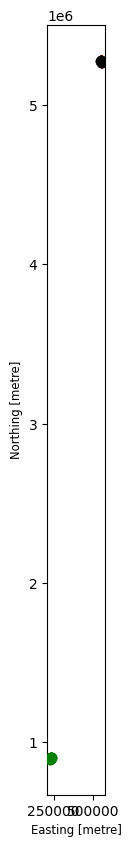

In [266]:
# original suitable roads
base = suitable_roads.plot(color='yellow', figsize=(10, 10),zorder=1)

# non-overlapping buffers
GoodLocationsGas_buffered_gdf.plot(ax=base, edgecolor='red', marker="+", facecolor='none',zorder=2)

# center points of the buffers
GoodLocationsGas_gdf.plot(ax=base, color='red', marker="+", markersize=50,zorder=3)

# all stations
fuelSeattle.plot(ax=base,color='k',zorder=4)
schoolBoston.plot(ax=base,color='green',zorder=5)

# stations to relocate
fuelBoston.clip(gas_relocate).plot(ax=base,color='magenta',zorder=5)


## Reverse geocoding

Just get some addresses:

In [ ]:
from geopy.geocoders import Nominatim
import time

# Initialize geocoder
geolocator = Nominatim(user_agent="Seattle_gas_stations")

def get_address(point):
  # Now coordinates are in degrees (lon, lat)
  lon = point.x
  lat = point.y
  location = geolocator.reverse((lat, lon), exactly_one=True, timeout=10)
  time.sleep(1)  # Rate limiting

  if location:
    return location.address
  else:
    return None # not found

In [270]:
from geopy.geocoders import Nominatim
import time

# Asegurar la inicialización del geocodificador
geolocator = Nominatim(user_agent="Seattle_gas_stations")

def get_address(point):
    # Las coordenadas deben estar en grados (lon, lat)
    lon = point.x
    lat = point.y
    try:
        location = geolocator.reverse((lat, lon), exactly_one=True, timeout=10)
        time.sleep(1)  # Límite de tasa para evitar bloqueos del servicio de Nominatim
        if location:
            return location.address
    except Exception:
        pass
    return None

# Obtener las direcciones para las nuevas ubicaciones
GoodLocationsGas_4326 = GoodLocationsGas_gdf.to_crs('EPSG:4326')
GoodLocationsGas_gdf['address'] = GoodLocationsGas_4326.geometry.apply(get_address)
GoodLocationsGas_gdf

,geometry,address
0,POINT (549512.281 5275319.084),"Meta Westlake, 1101, Westlake Avenue North, We..."
0,POINT (550637.47 5276148.793),"1925, Eastlake Avenue East, Eastlake, Cascade,..."
0,POINT (549672.968 5272340.706),"Colman Dock, West Edge, Belltown, Seattle, Kin..."
0,POINT (546324.857 5265963.993),"Fauntleroy Way Southwest, Morgan Junction, Del..."
0,POINT (552249.101 5267612.327),"Fou Lee Market, 2050, South Columbian Way, Jef..."
0,POINT (550152.006 5264003.059),"SR 509, Seattle, King County, Washington, 9810..."
0,POINT (550091.056 5266879.496),"5506, 1st Avenue South, Georgetown, Seattle, K..."
0,POINT (552226.892 5284203.185),"2316, Northeast Northgate Way, Victory Heights..."
0,POINT (550274.222 5273079.459),"Parkour Area in Freeway Park, 700, Seneca Stre..."
0,POINT (551026.428 5270992.712),"I 5, Yesler Terrace, Seattle, King County, Was..."


In [271]:
GoodLocationsGas_gdf

,geometry,address
0,POINT (549512.281 5275319.084),"Meta Westlake, 1101, Westlake Avenue North, We..."
0,POINT (550637.47 5276148.793),"1925, Eastlake Avenue East, Eastlake, Cascade,..."
0,POINT (549672.968 5272340.706),"Colman Dock, West Edge, Belltown, Seattle, Kin..."
0,POINT (546324.857 5265963.993),"Fauntleroy Way Southwest, Morgan Junction, Del..."
0,POINT (552249.101 5267612.327),"Fou Lee Market, 2050, South Columbian Way, Jef..."
0,POINT (550152.006 5264003.059),"SR 509, Seattle, King County, Washington, 9810..."
0,POINT (550091.056 5266879.496),"5506, 1st Avenue South, Georgetown, Seattle, K..."
0,POINT (552226.892 5284203.185),"2316, Northeast Northgate Way, Victory Heights..."
0,POINT (550274.222 5273079.459),"Parkour Area in Freeway Park, 700, Seneca Stre..."
0,POINT (551026.428 5270992.712),"I 5, Yesler Terrace, Seattle, King County, Was..."


______

[BACK TO MAIN MENU](https://cienciadedatosespacial.github.io/GDF_OPS_applications/)